In [1]:
import json
import pickle
from datetime import datetime
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, accuracy_score,
    average_precision_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
from clases_po import HFDatasetLoader

OBJETIVO = "default.payment.next.month"
COLORES = {"paga": "#1f6fe5", "incumple": "#e5384b", "naranja": "#f2661b", "verde": "#10a179", "morado": "#8a3ff0"}
SEMILLA = 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)

d:\IUDigital\2026\q4\machine learning\repositorios\ML_2026Q4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Etapa 1 · Extracción  → escena 2
Un banco de Taiwán registró seis meses (abril a septiembre de 2005) de **30 000 clientes de tarjeta de crédito**.
El dataset está en Hugging Face como `scikit-learn/credit-card-clients` (Yeh y Lien, 2009).
Lo cargamos igual que en las clases anteriores.

In [2]:
loader = HFDatasetLoader(dataset_name="scikit-learn/credit-card-clients", split="train",
                         filename="datos/credit_card_clients.csv")
df_credito_crudo = loader.load()   # 1 · cargar

print("Forma (filas, columnas):", df_credito_crudo.shape)
df_credito_crudo.head()

Forma (filas, columnas): (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102.0,689.0,0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682,1725.0,2682.0,3272,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239,14027.0,13559.0,14331,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990,48233.0,49291.0,28314,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617,5670.0,35835.0,20940,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


In [3]:
diccionario = pd.DataFrame([
    ("ID", "identificador del cliente", "no se usa para entrenar"),
    ("LIMIT_BAL", "cupo de crédito", "¿cuánto le prestaste?"),
    ("SEX", "1 = hombre, 2 = mujer", "¿quién es? (variable sensible)"),
    ("EDUCATION", "1 posgrado, 2 universidad, 3 bachillerato, 4 otros", "¿quién es?"),
    ("MARRIAGE", "1 casado, 2 soltero, 3 otros", "¿quién es? (variable sensible)"),
    ("AGE", "edad en años", "¿quién es?"),
    ("PAY_0 … PAY_6", "estado del pago de cada mes", "¿cómo ha pagado?"),
    ("BILL_AMT1 … BILL_AMT6", "valor facturado de cada mes", "¿cuánto debe?"),
    ("PAY_AMT1 … PAY_AMT6", "valor abonado de cada mes", "¿cuánto abonó?"),
    (OBJETIVO, "1 = no pagó el mes siguiente", "la respuesta: y"),
], columns=["columna", "significado", "pregunta del banco"])
diccionario

,columna,significado,pregunta del banco
0,ID,identificador del cliente,no se usa para entrenar
1,LIMIT_BAL,cupo de crédito,¿cuánto le prestaste?
2,SEX,"1 = hombre, 2 = mujer",¿quién es? (variable sensible)
3,EDUCATION,"1 posgrado, 2 universidad, 3 bachillerato, 4 o...",¿quién es?
4,MARRIAGE,"1 casado, 2 soltero, 3 otros",¿quién es? (variable sensible)
5,AGE,edad en años,¿quién es?
6,PAY_0 … PAY_6,estado del pago de cada mes,¿cómo ha pagado?
7,BILL_AMT1 … BILL_AMT6,valor facturado de cada mes,¿cuánto debe?
8,PAY_AMT1 … PAY_AMT6,valor abonado de cada mes,¿cuánto abonó?
9,default.payment.next.month,1 = no pagó el mes siguiente,la respuesta: y


In [4]:
df_credito_crudo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  int64  
 13  BILL_AMT2                   300

## Etapa 2 · Preprocesamiento  → escena 3
### 2.1 Validar antes de confiar
Cada validación produce una **métrica** y una **decisión**.

In [5]:
df = df_credito_crudo.copy()
n = len(df)
sin_id = df.drop(columns=["ID"], errors="ignore")   # el ID es único: los duplicados se buscan sin él

fuera_edu = ~df["EDUCATION"].isin([1, 2, 3, 4])
fuera_mar = ~df["MARRIAGE"].isin([1, 2, 3])
factura_neg = (df.filter(like="BILL_AMT") < 0).any(axis=1)

calidad = pd.DataFrame([
    ("Completitud · nulos", int(df.isna().sum().sum()), "continuar"),
    ("Unicidad · filas duplicadas (sin ID)", int(sin_id.duplicated().sum()), "eliminar"),
    ("Dominio · EDUCATION fuera de 1–4", int(fuera_edu.sum()), "agrupar en 4 = otros"),
    ("Dominio · MARRIAGE fuera de 1–3", int(fuera_mar.sum()), "agrupar en 3 = otros"),
    ("Consistencia · alguna factura negativa", int(factura_neg.sum()), "saldo a favor: se deja"),
], columns=["validación", "resultado", "decisión"])
calidad["métrica (%)"] = (calidad["resultado"] / n * 100).round(2)
calidad[["validación", "resultado", "métrica (%)", "decisión"]]

,validación,resultado,métrica (%),decisión
0,Completitud · nulos,0,0.00,continuar
1,Unicidad · filas duplicadas (sin ID),35,0.12,eliminar
2,Dominio · EDUCATION fuera de 1–4,345,1.15,agrupar en 4 = otros
3,Dominio · MARRIAGE fuera de 1–3,54,0.18,agrupar en 3 = otros
4,Consistencia · alguna factura negativa,1930,6.43,saldo a favor: se deja


In [6]:
print("EDUCATION:", df["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE: ", df["MARRIAGE"].value_counts().sort_index().to_dict())
print("PAY_0:    ", df["PAY_0"].value_counts().sort_index().to_dict())

EDUCATION: {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE:  {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0:     {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}


### 2.2 Limpiar con reglas que se puedan repetir
Cada transformación queda registrada: cuántas filas entran y cuántas salen.

In [7]:
registro = [("datos crudos", len(df))]

df = df.loc[~df.drop(columns=["ID"], errors="ignore").duplicated()].copy()
registro.append(("sin duplicados", len(df)))

df["EDUCATION"] = df["EDUCATION"].where(df["EDUCATION"].isin([1, 2, 3, 4]), 4)
df["MARRIAGE"] = df["MARRIAGE"].where(df["MARRIAGE"].isin([1, 2, 3]), 3)
registro.append(("EDUCATION y MARRIAGE recodificados", len(df)))

pd.DataFrame(registro, columns=["paso", "filas"])

,paso,filas
0,datos crudos,30000
1,sin duplicados,29965
2,EDUCATION y MARRIAGE recodificados,29965


### 2.3 Describir
**Tasa de incumplimiento** = clientes que incumplen ÷ total de clientes. Es tu riesgo base.

Cuando la **media** se aleja mucho de la **mediana**, unos pocos valores extremos están jalando el promedio.

In [8]:
print(df[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]].describe().round(0))

tasa = df[OBJETIVO].mean()
print(f"\nTasa de incumplimiento: {df[OBJETIVO].sum():,} de {len(df):,} = {tasa:.1%}")
print(f"Un modelo que siempre diga «paga» acertaría el {1 - tasa:.1%}")

       LIMIT_BAL      AGE  BILL_AMT1  PAY_AMT1
count    29965.0  29965.0    29965.0   29965.0
mean    167442.0     35.0    51283.0    5670.0
std     129760.0      9.0    73658.0   16572.0
min      10000.0     21.0  -165580.0       0.0
25%      50000.0     28.0     3595.0    1000.0
50%     140000.0     34.0    22438.0    2102.0
75%     240000.0     41.0    67260.0    5008.0
max    1000000.0     79.0   964511.0  873552.0

Tasa de incumplimiento: 6,630 de 29,965 = 22.1%
Un modelo que siempre diga «paga» acertaría el 77.9%


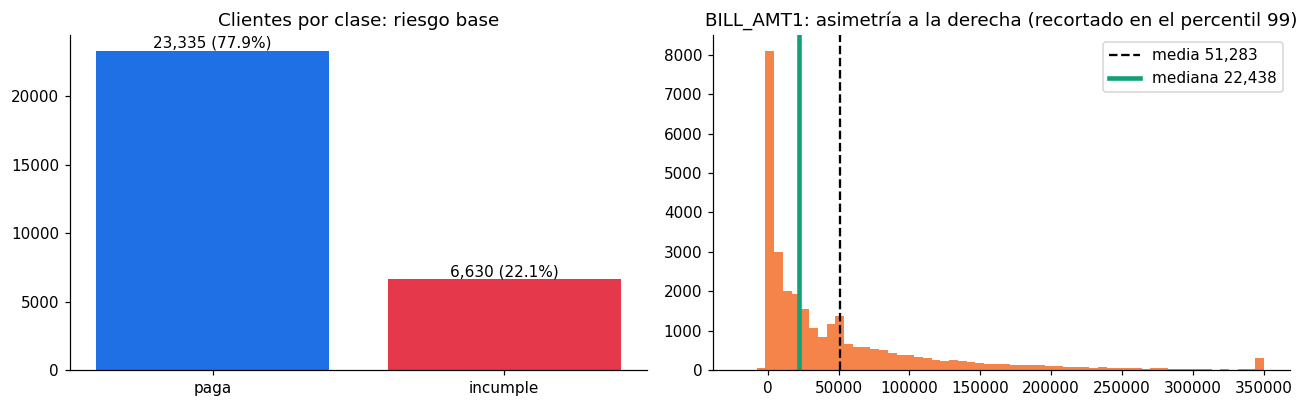

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
conteo = df[OBJETIVO].map({0: "paga", 1: "incumple"}).value_counts()
barras = ejes[0].bar(conteo.index, conteo.values, color=[COLORES[c] for c in conteo.index])
ejes[0].bar_label(barras, labels=[f"{v:,} ({v / len(df):.1%})" for v in conteo.values])
ejes[0].set_title("Clientes por clase: riesgo base")

tope = df["BILL_AMT1"].quantile(0.99)
ejes[1].hist(df["BILL_AMT1"].clip(-20_000, tope), bins=60, color=COLORES["naranja"], alpha=.8)
ejes[1].axvline(df["BILL_AMT1"].mean(), color="black", ls="--", label=f"media {df['BILL_AMT1'].mean():,.0f}")
ejes[1].axvline(df["BILL_AMT1"].median(), color=COLORES["verde"], lw=3, label=f"mediana {df['BILL_AMT1'].median():,.0f}")
ejes[1].set_title("BILL_AMT1: asimetría a la derecha (recortado en el percentil 99)")
ejes[1].legend()
plt.tight_layout()
plt.show()

### 2.4 Preguntarle a los datos
Antes de cualquier modelo, respondemos las preguntas del banco con tasas de incumplimiento por grupo.

**Utilización del cupo:** u = BILL_AMT1 ÷ LIMIT_BAL

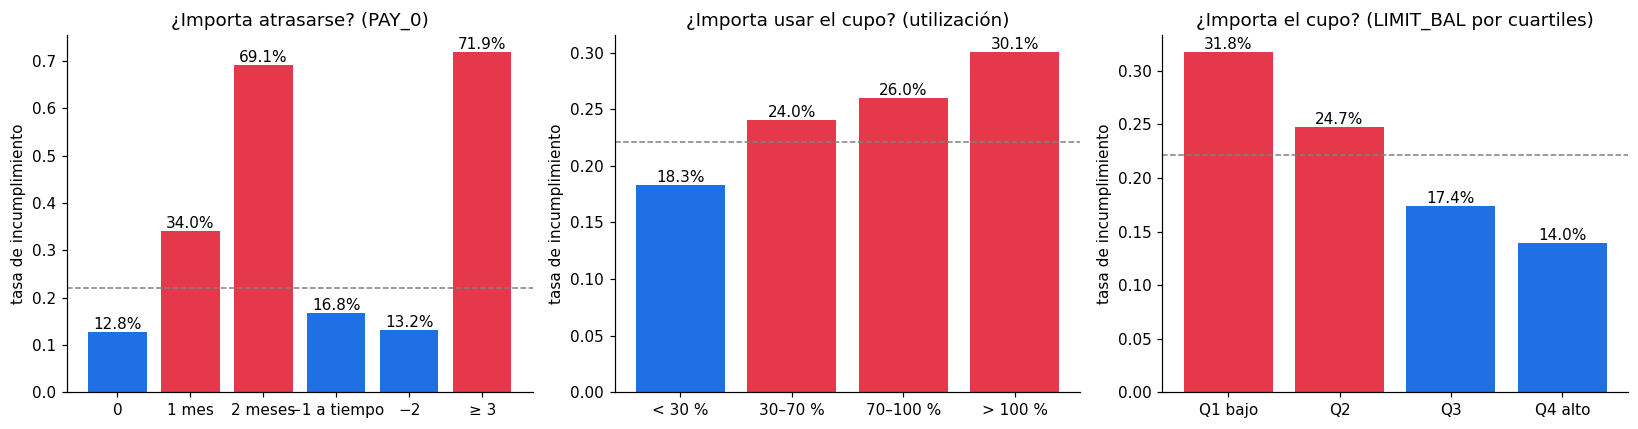

Línea gris: riesgo base. Inferencia: el pasado de pagos predice el futuro y el endeudamiento suma.


In [10]:
df["utilizacion"] = df["BILL_AMT1"] / df["LIMIT_BAL"]

grupos = {
    "¿Importa atrasarse? (PAY_0)": df["PAY_0"].clip(-2, 3).map(
        {-2: "−2", -1: "−1 a tiempo", 0: "0", 1: "1 mes", 2: "2 meses", 3: "≥ 3"}),
    "¿Importa usar el cupo? (utilización)": pd.cut(
        df["utilizacion"], [-np.inf, .3, .7, 1, np.inf], labels=["< 30 %", "30–70 %", "70–100 %", "> 100 %"]),
    "¿Importa el cupo? (LIMIT_BAL por cuartiles)": pd.qcut(
        df["LIMIT_BAL"], 4, labels=["Q1 bajo", "Q2", "Q3", "Q4 alto"]),
}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, (titulo, grupo) in zip(ejes, grupos.items()):
    t = df.groupby(grupo, observed=True)[OBJETIVO].mean()
    barras = eje.bar(t.index.astype(str), t.values, color=[COLORES["incumple"] if v > tasa else COLORES["paga"] for v in t.values])
    eje.bar_label(barras, labels=[f"{v:.1%}" for v in t.values])
    eje.axhline(tasa, color="gray", ls="--", lw=1)
    eje.set_title(titulo)
    eje.set_ylabel("tasa de incumplimiento")
plt.tight_layout()
plt.show()
print("Línea gris: riesgo base. Inferencia: el pasado de pagos predice el futuro y el endeudamiento suma.")

### Variables sensibles
SEX y MARRIAGE están en los datos. Que estén no significa que debamos usarlas para decidir:
primero medimos si el riesgo cambia entre grupos y, al final, revisamos si el modelo trata distinto a cada grupo.

In [11]:
print(df.groupby("SEX")[OBJETIVO].mean().rename({1: "hombre", 2: "mujer"}).round(3))

SEX
hombre    0.242
mujer     0.208
Name: default.payment.next.month, dtype: float64


## Etapa 3 · Entrenamiento  → escena 4
### 3.1 Separar: los clientes del futuro
El 20 % se guarda como **prueba** y el modelo no la ve hasta el final.
`stratify=y` conserva la misma proporción de incumplimiento en ambas partes.

La `utilizacion` fue un indicador para explorar; el modelo usa las 23 variables originales.

<!-- ### 10 · Ejemplos de errores  ->  discusión en clase -->

In [13]:
X = df.drop(columns=["ID", OBJETIVO, "utilizacion"], errors="ignore")
y = df[OBJETIVO]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEMILLA)

pd.DataFrame({"clientes": [len(y_tr), len(y_te)],
              "tasa de incumplimiento": [f"{y_tr.mean():.2%}", f"{y_te.mean():.2%}"]},
             index=["entrenamiento", "prueba"])

,clientes,tasa de incumplimiento
entrenamiento,23972,22.13%
prueba,5993,22.13%


### 3.2 Cómo elige sus preguntas el árbol: Gini y ganancia
**G = 1 − Σ pₖ²**, donde K es el número de clases (aquí 2) y pₖ la proporción de la clase k en el nodo.

**G_corte = (n_izq / n) · G_izq + (n_der / n) · G_der** y **ganancia = G_padre − G_corte**.

In [14]:
def gini(etiquetas):
    p = np.bincount(etiquetas, minlength=2) / len(etiquetas)
    return 1 - np.sum(p ** 2)

def evaluar_corte(x, etiquetas, umbral):
    izq, der = etiquetas[x <= umbral], etiquetas[x > umbral]
    g_corte = len(izq) / len(etiquetas) * gini(izq) + len(der) / len(etiquetas) * gini(der)
    return g_corte, gini(etiquetas) - g_corte

y_arr = y_tr.to_numpy()
print(f"Gini de la raíz: {gini(y_arr):.3f}")
filas = []
for u in [-1.5, -0.5, 0.5, 1.5, 2.5]:
    g, gan = evaluar_corte(X_tr["PAY_0"].to_numpy(), y_arr, u)
    filas.append({"corte": f"PAY_0 ≤ {u}", "Gini ponderado": round(g, 4), "ganancia": round(gan, 4)})
pd.DataFrame(filas)

Gini de la raíz: 0.345


,corte,Gini ponderado,ganancia
0,PAY_0 ≤ -1.5,0.3430,0.0016
1,PAY_0 ≤ -0.5,0.3415,0.0031
2,PAY_0 ≤ 0.5,0.2971,0.0475
3,PAY_0 ≤ 1.5,0.2916,0.0530
4,PAY_0 ≤ 2.5,0.3369,0.0077


In [15]:
# El mejor corte de cada variable: ¿cuál gana?
mejores = []
for col in X_tr.columns:
    x = X_tr[col].to_numpy()
    candidatos = np.unique(np.quantile(x, np.linspace(0, 1, 101)))
    umbrales = (candidatos[:-1] + candidatos[1:]) / 2
    if len(umbrales) == 0:
        continue
    res = [evaluar_corte(x, y_arr, u) for u in umbrales]
    k = int(np.argmax([r[1] for r in res]))
    mejores.append({"variable": col, "umbral": umbrales[k], "ganancia": res[k][1]})
pd.DataFrame(mejores).sort_values("ganancia", ascending=False).head(8).round(4)

,variable,umbral,ganancia
5,PAY_0,1.50,0.0530
6,PAY_2,1.00,0.0400
7,PAY_3,1.53,0.0300
8,PAY_4,1.00,0.0260
9,PAY_5,1.00,0.0239
10,PAY_6,1.00,0.0201
17,PAY_AMT1,12.50,0.0090
0,LIMIT_BAL,125000.00,0.0079


### 3.3 Elegir la profundidad con validación cruzada (sin tocar la prueba)
Cinco pliegues estratificados del entrenamiento. Miramos tres cosas:
**promedio**, **variación entre pliegues** y **brecha** entre entrenamiento y validación.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
filas = []
for prof in [1, 2, 3, 4, 5, 6, 8, 12, None]:
    r = cross_validate(DecisionTreeClassifier(max_depth=prof, random_state=SEMILLA), X_tr, y_tr,
                       cv=cv, scoring="roc_auc", return_train_score=True)
    filas.append({"max_depth": "sin límite" if prof is None else prof,
                  "AUC entrenamiento": r["train_score"].mean(), "AUC validación": r["test_score"].mean(),
                  "desviación": r["test_score"].std()})
validacion = pd.DataFrame(filas)
validacion["brecha"] = validacion["AUC entrenamiento"] - validacion["AUC validación"]
validacion.round(3)

,max_depth,AUC entrenamiento,AUC validación,desviación,brecha
0,1,0.645,0.645,0.006,-0.000
1,2,0.695,0.695,0.006,0.000
2,3,0.738,0.732,0.005,0.006
3,4,0.752,0.744,0.007,0.008
4,5,0.768,0.758,0.007,0.010
5,6,0.779,0.758,0.006,0.020
6,8,0.802,0.749,0.007,0.053
7,12,0.872,0.686,0.009,0.186
8,sin límite,1.000,0.614,0.006,0.386


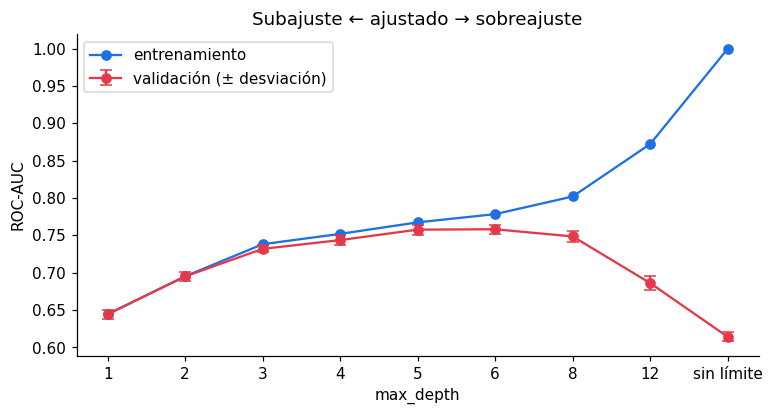

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8))
etiquetas = validacion["max_depth"].astype(str)
ax.plot(etiquetas, validacion["AUC entrenamiento"], "o-", color=COLORES["paga"], label="entrenamiento")
ax.errorbar(etiquetas, validacion["AUC validación"], yerr=validacion["desviación"], fmt="o-",
            color=COLORES["incumple"], capsize=4, label="validación (± desviación)")
ax.set_xlabel("max_depth")
ax.set_ylabel("ROC-AUC")
ax.set_title("Subajuste ← ajustado → sobreajuste")
ax.legend()
plt.show()

### 3.4 Entrenar el modelo elegido y leer sus reglas

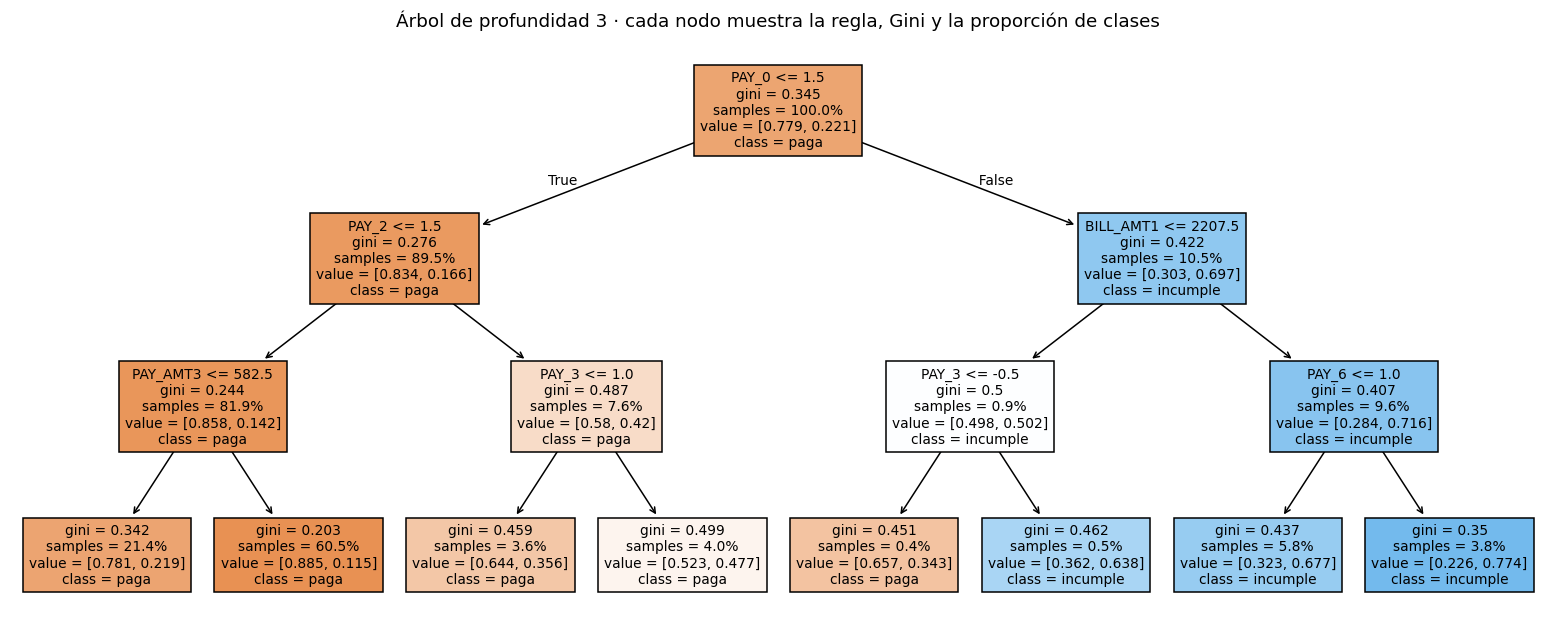

In [18]:
arbol = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA).fit(X_tr, y_tr)

plt.figure(figsize=(18, 7))
plot_tree(arbol, feature_names=X.columns, class_names=["paga", "incumple"], filled=True,
          proportion=True, impurity=True, fontsize=9)
plt.title("Árbol de profundidad 3 · cada nodo muestra la regla, Gini y la proporción de clases")
plt.show()

## Etapa 4 · Análisis y métricas  → escena 5
### 4.1 Exactitud contra el modelo perezoso

In [19]:
pred = arbol.predict(X_te)
proba = arbol.predict_proba(X_te)[:, 1]
perezoso = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)

print(f"Exactitud del árbol:                {accuracy_score(y_te, pred):.1%}")
print(f"Exactitud de responder siempre paga: {accuracy_score(y_te, perezoso.predict(X_te)):.1%}")

Exactitud del árbol:                81.8%
Exactitud de responder siempre paga: 77.9%


### 4.2 Matriz de confusión en lenguaje de banco
- **VN** buenos clientes aprobados · **FP** buenos clientes rechazados
- **FN** morosos aprobados (el error que cuesta dinero) · **VP** morosos detectados

**Recall** = VP ÷ (VP + FN) · **Precisión** = VP ÷ (VP + FP)

Buenos aprobados (VN): 4,487 · buenos rechazados (FP): 180
Morosos aprobados (FN): 908 · morosos detectados (VP): 418

Recall    = 418 / (418 + 908) = 31.5%
Precisión = 418 / (418 + 180) = 69.9%


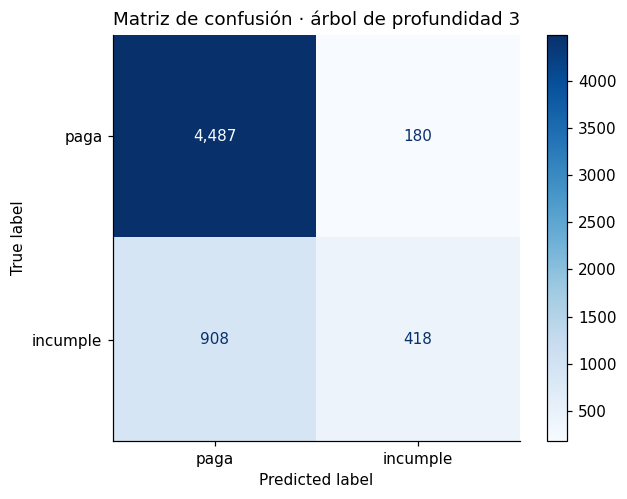

              precision    recall  f1-score   support

        paga      0.832     0.961     0.892      4667
    incumple      0.699     0.315     0.435      1326

    accuracy                          0.818      5993
   macro avg      0.765     0.638     0.663      5993
weighted avg      0.802     0.818     0.791      5993



In [20]:
vn, fp, fn, vp = confusion_matrix(y_te, pred).ravel()
print(f"Buenos aprobados (VN): {vn:,} · buenos rechazados (FP): {fp:,}")
print(f"Morosos aprobados (FN): {fn:,} · morosos detectados (VP): {vp:,}")
print(f"\nRecall    = {vp} / ({vp} + {fn}) = {vp / (vp + fn):.1%}")
print(f"Precisión = {vp} / ({vp} + {fp}) = {vp / (vp + fp):.1%}")

ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["paga", "incumple"],
                                        cmap="Blues", values_format=",d")
plt.title("Matriz de confusión · árbol de profundidad 3")
plt.show()

print(classification_report(y_te, pred, target_names=["paga", "incumple"], digits=3))


### 4.3 ¿Qué tan bien ordena de más a menos riesgo?
**ROC-AUC**: 0,5 es azar y 1 es perfecto. **PR-AUC** (precisión media): se compara con la tasa base.

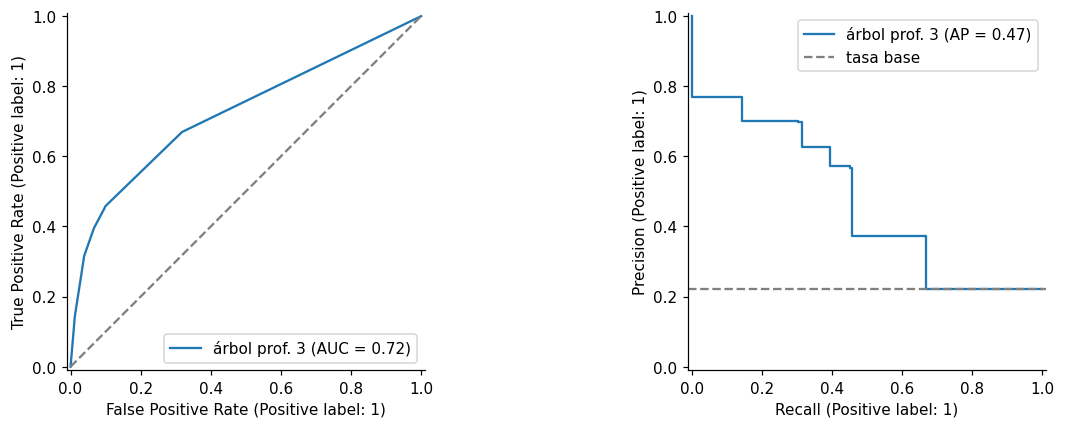

ROC-AUC: 0.723 · PR-AUC: 0.469 (tasa base 0.221)


In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
RocCurveDisplay.from_predictions(y_te, proba, ax=ejes[0], name="árbol prof. 3")
ejes[0].plot([0, 1], [0, 1], "--", color="gray")
PrecisionRecallDisplay.from_predictions(y_te, proba, ax=ejes[1], name="árbol prof. 3")
ejes[1].axhline(y_te.mean(), ls="--", color="gray", label="tasa base")
ejes[1].legend()
plt.tight_layout()
plt.show()
print(f"ROC-AUC: {roc_auc_score(y_te, proba):.3f} · PR-AUC: {average_precision_score(y_te, proba):.3f} (tasa base {y_te.mean():.3f})")

### 4.4 Escenarios: sobreajuste, subajuste, ajustado y balanceado

In [22]:
escenarios = {
    "1 · sin límite": DecisionTreeClassifier(random_state=SEMILLA),
    "2 · profundidad 2": DecisionTreeClassifier(max_depth=2, random_state=SEMILLA),
    "3 · profundidad 3": DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    "4 · prof. 3 balanceado": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=SEMILLA),
}
filas = []
for nombre, modelo in escenarios.items():
    modelo.fit(X_tr, y_tr)
    p_tr, p_te = modelo.predict(X_tr), modelo.predict(X_te)
    filas.append({"escenario": nombre, "hojas": modelo.get_n_leaves(),
                  "exactitud entrenamiento": accuracy_score(y_tr, p_tr), "exactitud prueba": accuracy_score(y_te, p_te),
                  "recall": recall_score(y_te, p_te), "precisión": precision_score(y_te, p_te),
                  "F1": f1_score(y_te, p_te), "ROC-AUC": roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1]),
                  "buenos rechazados": int(((p_te == 1) & (y_te == 0)).sum()),
                  "morosos aprobados": int(((p_te == 0) & (y_te == 1)).sum())})
tabla_escenarios = pd.DataFrame(filas).set_index("escenario")
tabla_escenarios.round(3)


,hojas,exactitud entrenamiento,exactitud prueba,recall,precisión,F1,ROC-AUC,buenos rechazados,morosos aprobados
escenario,,,,,,,,,
1 · sin límite,3815,0.999,0.727,0.410,0.388,0.399,0.613,857,782
2 · profundidad 2,4,0.820,0.818,0.322,0.688,0.439,0.686,194,899
3 · profundidad 3,8,0.821,0.818,0.315,0.699,0.435,0.723,180,908
4 · prof. 3 balanceado,8,0.753,0.748,0.587,0.447,0.508,0.735,962,547


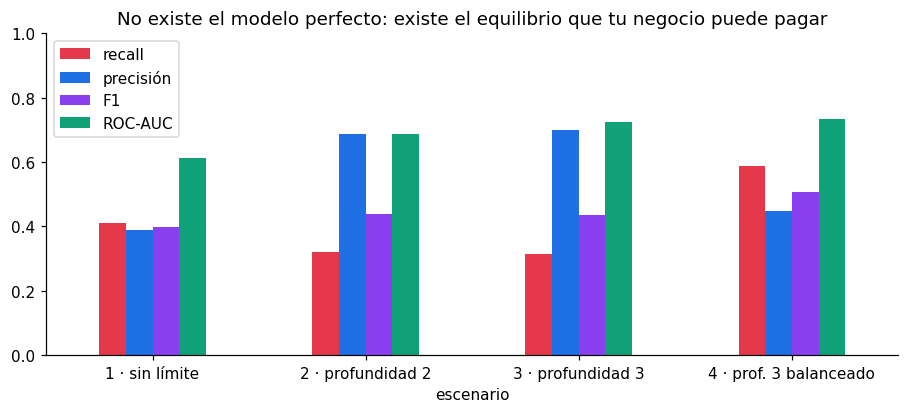

In [23]:
tabla_escenarios[["recall", "precisión", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(10, 3.8), rot=0,
    color=[COLORES["incumple"], COLORES["paga"], COLORES["morado"], COLORES["verde"]],
    title="No existe el modelo perfecto: existe el equilibrio que tu negocio puede pagar")
plt.ylim(0, 1)
plt.show()

### 4.5 ¿Qué variables usa el modelo? ¿Trata igual a todos?

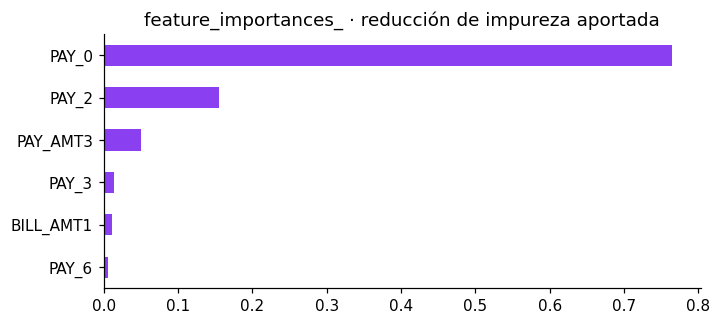

,recall,tasa marcada como riesgo
hombre,0.309,0.108
mujer,0.320,0.094


In [24]:
importancias = pd.Series(arbol.feature_importances_, index=X.columns)
importancias[importancias > 0].sort_values().plot(kind="barh", color=COLORES["morado"], figsize=(7, 3),
                                                  title="feature_importances_ · reducción de impureza aportada")
plt.show()

equidad = pd.DataFrame({sexo: {"recall": recall_score(y_te[X_te["SEX"] == k], pred[X_te["SEX"] == k]),
                               "tasa marcada como riesgo": pred[X_te["SEX"] == k].mean()}
                        for k, sexo in [(1, "hombre"), (2, "mujer")]}).T
equidad.round(3)